# RecruitGen — Model 2 of 3: CVAE (Synthetic Candidate Generation & Role Fit)

**Goal:** learn candidate representations and generate synthetic candidate profiles conditioned on a target job role.

```
Candidate Features → Preprocessing → Encoder → Latent Space → Decoder + Condition → Synthetic Candidate
```

* **Input features:** Experience, Projects, Skills, AI Score, Education, Certifications, Job Role, Recruiter Decision
* **Preprocessing:** MultiLabelBinarizer (skills) · OneHotEncoder (job role condition) · StandardScaler (numerical features)
* **Reparameterization** enables sampling from the latent space; the condition steers generation.

**Outputs:** `vae_model.h5`, `vae.weights.h5`, `scaler.json`.

## 1. Setup

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
import keras
from keras import layers, ops

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

QUICK_RUN = False
N_CANDIDATES = 600 if QUICK_RUN else 6000
EPOCHS = 3 if QUICK_RUN else 150
BATCH_SIZE = 64
LATENT_DIM = 8
BETA = 1.0                     # weight of the KL term

DATA_PATH = "data/candidates.csv"   # optional real dataset
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ROLES = ["AI/ML Engineer", "Cloud Engineer", "Data Analyst", "General IT", "Software Engineer"]
FEATURES = ["experience_years", "projects_count", "programming_score", "data_analytics_score", "ml_ai_score",
            "cloud_score", "communication_score", "certification_count", "education_level"]

## 2. Candidate structured dataset

Columns: Experience, Skills, Education, Certifications, Job Role, Projects, AI Score, Recruiter Decision.
If `data/candidates.csv` exists it is loaded; otherwise a realistic dataset is simulated with
role-specific skill distributions.

In [2]:
SKILL_POOL = {
    "programming": ["Python", "Java", "C++", "JavaScript", "Go", "Git", "REST APIs", "OOP"],
    "data": ["SQL", "Excel", "Power BI", "Tableau", "Pandas", "Statistics", "Data Visualization"],
    "ml": ["TensorFlow", "PyTorch", "Scikit-learn", "NLP", "Computer Vision", "Deep Learning", "LLMs"],
    "cloud": ["AWS", "Azure", "GCP", "Docker", "Kubernetes", "Terraform", "CI/CD"],
    "soft": ["Communication", "Teamwork", "Leadership", "Presentation", "Problem Solving"],
}
ROLE_FOCUS = {
    "AI/ML Engineer":    {"programming": 4, "data": 2, "ml": 5, "cloud": 1, "soft": 2},
    "Cloud Engineer":    {"programming": 3, "data": 1, "ml": 1, "cloud": 5, "soft": 2},
    "Data Analyst":      {"programming": 2, "data": 5, "ml": 1, "cloud": 1, "soft": 3},
    "General IT":        {"programming": 2, "data": 2, "ml": 1, "cloud": 2, "soft": 3},
    "Software Engineer": {"programming": 5, "data": 1, "ml": 1, "cloud": 2, "soft": 2},
}
EDUCATION = ["Diploma", "Bachelor's", "Master's", "PhD"]

def simulate(n):
    rows = []
    for _ in range(n):
        role = random.choice(ROLES)
        skills = []
        for group, k in ROLE_FOCUS[role].items():
            skills += random.sample(SKILL_POOL[group], min(len(SKILL_POOL[group]), max(0, int(np.random.normal(k, 1)))))
        exp = round(max(0, np.random.gamma(2.0, 2.0)), 1)
        rows.append({
            "Experience (Years)": exp,
            "Skills": ", ".join(sorted(set(skills))),
            "Education": np.random.choice(EDUCATION, p=[0.1, 0.62, 0.24, 0.04]),
            "Certifications": int(np.random.poisson(1 + exp / 3)),
            "Job Role": role,
            "Projects Count": int(np.random.poisson(2 + exp / 2)),
            "AI Score (0-100)": int(np.clip(np.random.normal(60 + 6 * len(skills) / 4, 12), 0, 100)),
        })
    df = pd.DataFrame(rows)
    df["Recruiter Decision"] = np.where(df["AI Score (0-100)"] + np.random.normal(0, 8, len(df)) > 65, "Hire", "Reject")
    return df

raw = pd.read_csv(DATA_PATH) if os.path.exists(DATA_PATH) else simulate(N_CANDIDATES)
raw.head()

,Experience (Years),Skills,Education,Certifications,Job Role,Projects Count,AI Score (0-100),Recruiter Decision
0,2.8,"AWS, C++, Communication, Computer Vision, Deep...",Master's,2,AI/ML Engineer,3,72,Reject
1,2.3,"Computer Vision, Go, Java, JavaScript, LLMs, P...",Bachelor's,1,AI/ML Engineer,2,64,Reject
2,10.8,"Communication, GCP, Java, JavaScript, Pandas, ...",Bachelor's,2,Software Engineer,11,56,Reject
3,1.2,"Azure, GCP, Leadership, Power BI, REST APIs, T...",Diploma,2,Cloud Engineer,0,70,Hire
4,2.0,"AWS, C++, Computer Vision, Data Visualization,...",Master's,2,AI/ML Engineer,3,78,Hire


## 3. Preprocessing — MultiLabelBinarizer · OneHotEncoder · StandardScaler

In [3]:
# Skills -> multi-hot matrix
mlb = MultiLabelBinarizer()
skills_mh = pd.DataFrame(mlb.fit_transform(raw["Skills"].fillna("").str.split(r",\s*")), columns=mlb.classes_)

def group_score(group):
    cols = [s for s in SKILL_POOL[group] if s in skills_mh.columns]
    return (skills_mh[cols].sum(axis=1) / len(SKILL_POOL[group]) * 100).clip(0, 100)

edu_map = {"Diploma": 1, "Bachelor's": 2, "Master's": 3, "PhD": 5}
data = pd.DataFrame({
    "experience_years": raw["Experience (Years)"].astype(float),
    "projects_count": raw["Projects Count"].astype(float),
    "programming_score": group_score("programming"),
    "data_analytics_score": group_score("data"),
    "ml_ai_score": group_score("ml"),
    "cloud_score": group_score("cloud"),
    "communication_score": group_score("soft"),
    "certification_count": raw["Certifications"].astype(float),
    "education_level": raw["Education"].map(edu_map).fillna(2).astype(float),
})

# Job role -> one-hot condition vector
ohe = OneHotEncoder(categories=[ROLES], sparse_output=False)
C = ohe.fit_transform(raw[["Job Role"]]).astype("float32")

# Numerical features -> StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(data[FEATURES]).astype("float32")

X_train, X_val, C_train, C_val = train_test_split(X, C, test_size=0.2, random_state=SEED, stratify=raw["Job Role"])
print("X", X.shape, "| condition", C.shape)
data.describe().round(2)

X (6000, 9) | condition (6000, 5)


,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
count,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,4.05,4.00,33.85,25.39,20.96,24.98,38.45,2.35,2.27
std,2.88,2.45,19.23,23.68,25.11,23.89,22.43,1.80,0.79
min,0.10,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
25%,1.90,2.00,25.00,0.00,0.00,0.00,20.00,1.00,2.00
50%,3.40,4.00,37.50,14.29,14.29,14.29,40.00,2.00,2.00
75%,5.50,5.00,50.00,42.86,28.57,42.86,60.00,3.00,3.00
max,27.20,20.00,87.50,100.00,100.00,100.00,100.00,15.00,5.00


### Optional: train on the Kaggle Resume Dataset

**Kaggle Resume Dataset:** https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset

`Resume/Resume.csv` (`ID`, `Resume_str`, `Resume_html`, `Category` — 2,484 resumes, 24 categories) and
`data/data/<CATEGORY>/<ID>.pdf` (the same resumes as PDFs). Setup — pick one:

1. **Automatic:** the optional cell below calls `kagglehub.dataset_download("snehaanbhawal/resume-dataset")`
   (`pip install kagglehub`; add `~/.kaggle/kaggle.json` if Kaggle asks for authentication).
2. **Manual:** download the ZIP from the link and extract it to `RecruitGen/data/kaggle_resume/`.
3. **Kaggle CLI:** `kaggle datasets download -d snehaanbhawal/resume-dataset -p data/kaggle_resume --unzip` (run in `RecruitGen/`)

The dataset has **no** numerical features: they are extracted from `Resume_str` with the app's
`feature_extractor.py` (shared loader: `models/gan/dataset.py`). The condition becomes the 24 Kaggle categories
instead of the 5 RecruitGen roles, so weights trained this way do **not** fit the app's CVAE page (5 roles).
Keep `USE_KAGGLE = False` to reproduce the shipped `vae_model.h5`. A same-architecture CVAE trained on Kaggle data is
compared with the GAN in `models/gan/GAN_Training.ipynb`.

In [4]:
USE_KAGGLE = False

if USE_KAGGLE:
    import sys
    sys.path.insert(0, os.path.abspath(os.path.join("..", "..")))
    from models.gan import dataset as kaggle
    table, report = kaggle.build_feature_table(kaggle.load_raw(kaggle.find_resume_csv() or kaggle.download_dataset()))
    ROLES = sorted(table["job_role"].unique())
    data = table[FEATURES].reset_index(drop=True)
    ohe = OneHotEncoder(categories=[ROLES], sparse_output=False)
    C = ohe.fit_transform(table[["job_role"]]).astype("float32")
    scaler = StandardScaler()
    X = scaler.fit_transform(data[FEATURES]).astype("float32")
    X_train, X_val, C_train, C_val = train_test_split(X, C, test_size=0.2, random_state=SEED, stratify=table["job_role"])
    print("Kaggle:", report["rows"], "resumes | X", X.shape, "| condition", C.shape)

## 4. CVAE architecture (encoder · reparameterization · conditional decoder)

In [5]:
@keras.saving.register_keras_serializable(package="RecruitGen")
class Sampling(layers.Layer):
    """z = mean + exp(0.5 * log_var) * epsilon"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        return z_mean + ops.exp(0.5 * z_log_var) * keras.random.normal(ops.shape(z_mean))

INPUT_DIM, CONDITION_DIM = len(FEATURES), len(ROLES)

def build_cvae():
    x_in = keras.Input((INPUT_DIM,), name="candidate_features")
    c_in = keras.Input((CONDITION_DIM,), name="target_role")
    h = layers.Concatenate(name="encoder_condition")([x_in, c_in])
    h = layers.Dense(64, activation="relu", name="encoder_dense_1")(h)
    h = layers.Dense(32, activation="relu", name="encoder_dense_2")(h)
    z_mean = layers.Dense(LATENT_DIM, name="z_mean")(h)
    z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(h)
    z = Sampling(name="latent_sampling")([z_mean, z_log_var])
    h = layers.Concatenate(name="decoder_condition")([z, c_in])
    h = layers.Dense(32, activation="relu", name="decoder_dense_1")(h)
    h = layers.Dense(64, activation="relu", name="decoder_dense_2")(h)
    out = layers.Dense(INPUT_DIM, activation="sigmoid", name="candidate_reconstruction")(h)
    return keras.Model([x_in, c_in], out, name="RecruitGen_CVAE")

cvae = build_cvae()
encoder = keras.Model(cvae.inputs, [cvae.get_layer("z_mean").output, cvae.get_layer("z_log_var").output], name="cvae_encoder")
cvae.summary()

Model: "RecruitGen_CVAE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ candidate_features  │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_role         │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_condition   │ (None, 14)        │          0 │ candidate_featur… │
│ (Concatenate)       │                   │            │ target_role[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_1     │ (None, 64)        │        960 │ encoder_conditio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_2     │ (None, 32)        │      2,080 │ encoder_dense_1[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 8)         │        264 │ encoder_dense_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 8)         │        264 │ encoder_dense_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_sampling     │ (None, 8)         │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_condition   │ (None, 13)        │          0 │ latent_sampling[… │
│ (Concatenate)       │                   │            │ target_role[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense_1     │ (None, 32)        │        448 │ decoder_conditio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense_2     │ (None, 64)        │      2,112 │ decoder_dense_1[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ candidate_reconstr… │ (None, 9)         │        585 │ decoder_dense_2[… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,713 (26.22 KB)

 Trainable params: 6,713 (26.22 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Training — reconstruction loss + KL divergence

In [6]:
class CVAETrainer(keras.Model):
    def __init__(self, cvae, encoder, beta=1.0):
        super().__init__()
        self.cvae, self.encoder, self.beta = cvae, encoder, beta
        self.trackers = {k: keras.metrics.Mean(name=k) for k in ["loss", "reconstruction", "kl"]}

    @property
    def metrics(self):
        return list(self.trackers.values())

    def _compute_losses(self, x, c, training):
        z_mean, z_log_var = self.encoder([x, c], training=training)
        recon = self.cvae([x, c], training=training)
        rec = ops.mean(ops.sum(ops.square(x - recon), axis=1))
        kl = ops.mean(-0.5 * ops.sum(1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var), axis=1))
        return rec + self.beta * kl, rec, kl

    def _update(self, total, rec, kl):
        for k, v in zip(["loss", "reconstruction", "kl"], [total, rec, kl]):
            self.trackers[k].update_state(v)
        return {k: m.result() for k, m in self.trackers.items()}

    def train_step(self, data):
        x, c = data[0] if len(data) == 1 else data
        with tf.GradientTape() as tape:
            total, rec, kl = self._compute_losses(x, c, True)
        grads = tape.gradient(total, self.cvae.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.cvae.trainable_weights))
        return self._update(total, rec, kl)

    def test_step(self, data):
        x, c = data[0] if len(data) == 1 else data
        return self._update(*self._compute_losses(x, c, False))

trainer = CVAETrainer(cvae, encoder, beta=BETA)
trainer.compile(optimizer=keras.optimizers.Adam(1e-3))
history = trainer.fit(
    tf.data.Dataset.from_tensor_slices((X_train, C_train)).shuffle(4096, seed=SEED).batch(BATCH_SIZE),
    validation_data=tf.data.Dataset.from_tensor_slices((X_val, C_val)).batch(BATCH_SIZE),
    epochs=EPOCHS,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
    verbose=2,
)

Epoch 1/150


D:\RecruitGen_Final\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


75/75 - 2s - 23ms/step - kl: 0.0982 - loss: 10.1109 - reconstruction: 10.0127 - val_kl: 0.0446 - val_loss: 9.0311 - val_reconstruction: 8.9865


Epoch 2/150


75/75 - 0s - 3ms/step - kl: 0.0332 - loss: 8.9585 - reconstruction: 8.9253 - val_kl: 0.0270 - val_loss: 8.7088 - val_reconstruction: 8.6818


Epoch 3/150


... (75 outputs left out)

Epoch 41/150


75/75 - 0s - 2ms/step - kl: 0.0595 - loss: 7.1842 - reconstruction: 7.1246 - val_kl: 0.0571 - val_loss: 7.1531 - val_reconstruction: 7.0961


Epoch 42/150


75/75 - 0s - 2ms/step - kl: 0.0640 - loss: 7.1921 - reconstruction: 7.1281 - val_kl: 0.0553 - val_loss: 7.1663 - val_reconstruction: 7.1110


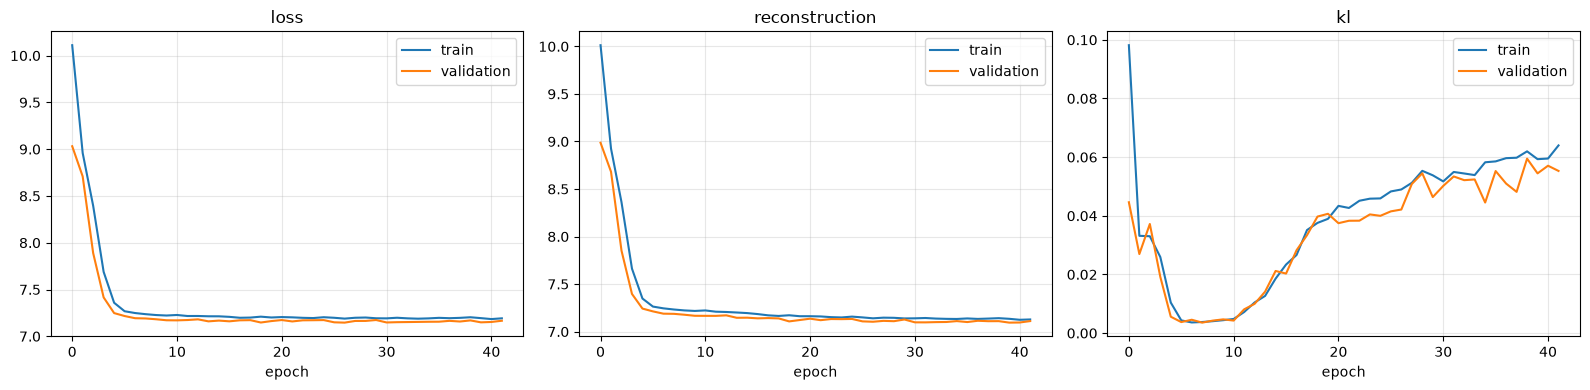

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, k in zip(ax, ["loss", "reconstruction", "kl"]):
    a.plot(history.history[k], label="train"); a.plot(history.history["val_" + k], label="validation")
    a.set_title(k); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Evaluation — reconstruction behaviour · synthetic candidate quality · feature-distribution consistency

In [8]:
rec_val = cvae.predict([X_val, C_val], verbose=0)
print("Validation reconstruction MSE:", float(np.mean((X_val - rec_val) ** 2)))

# Decoder only: latent z + role condition -> candidate
z_in = keras.Input((LATENT_DIM,)); c_in = keras.Input((CONDITION_DIM,))
h = cvae.get_layer("decoder_condition")([z_in, c_in])
h = cvae.get_layer("decoder_dense_2")(cvae.get_layer("decoder_dense_1")(h))
decoder = keras.Model([z_in, c_in], cvae.get_layer("candidate_reconstruction")(h), name="cvae_decoder")

def generate(role, n=500):
    c = np.zeros((n, CONDITION_DIM), "float32"); c[:, ROLES.index(role)] = 1
    z = np.random.normal(size=(n, LATENT_DIM)).astype("float32")
    return pd.DataFrame(decoder.predict([z, c], verbose=0) * scaler.scale_ + scaler.mean_, columns=FEATURES)

synthetic = {r: generate(r) for r in ROLES}
synthetic["AI/ML Engineer"].describe().round(2)

Validation reconstruction MSE: 0.786824107170105


,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,4.07,4.01,42.91,25.40,46.06,24.98,38.46,2.35,2.27
std,0.01,0.00,1.52,0.01,0.02,0.00,0.03,0.00,0.00
min,4.05,4.00,37.64,25.39,45.79,24.98,38.45,2.35,2.27
25%,4.06,4.00,41.88,25.39,46.06,24.98,38.45,2.35,2.27
50%,4.07,4.00,42.89,25.39,46.06,24.98,38.45,2.35,2.27
75%,4.08,4.01,43.93,25.40,46.06,24.98,38.46,2.36,2.27
max,4.12,4.03,47.00,25.53,46.06,25.00,38.73,2.37,2.28


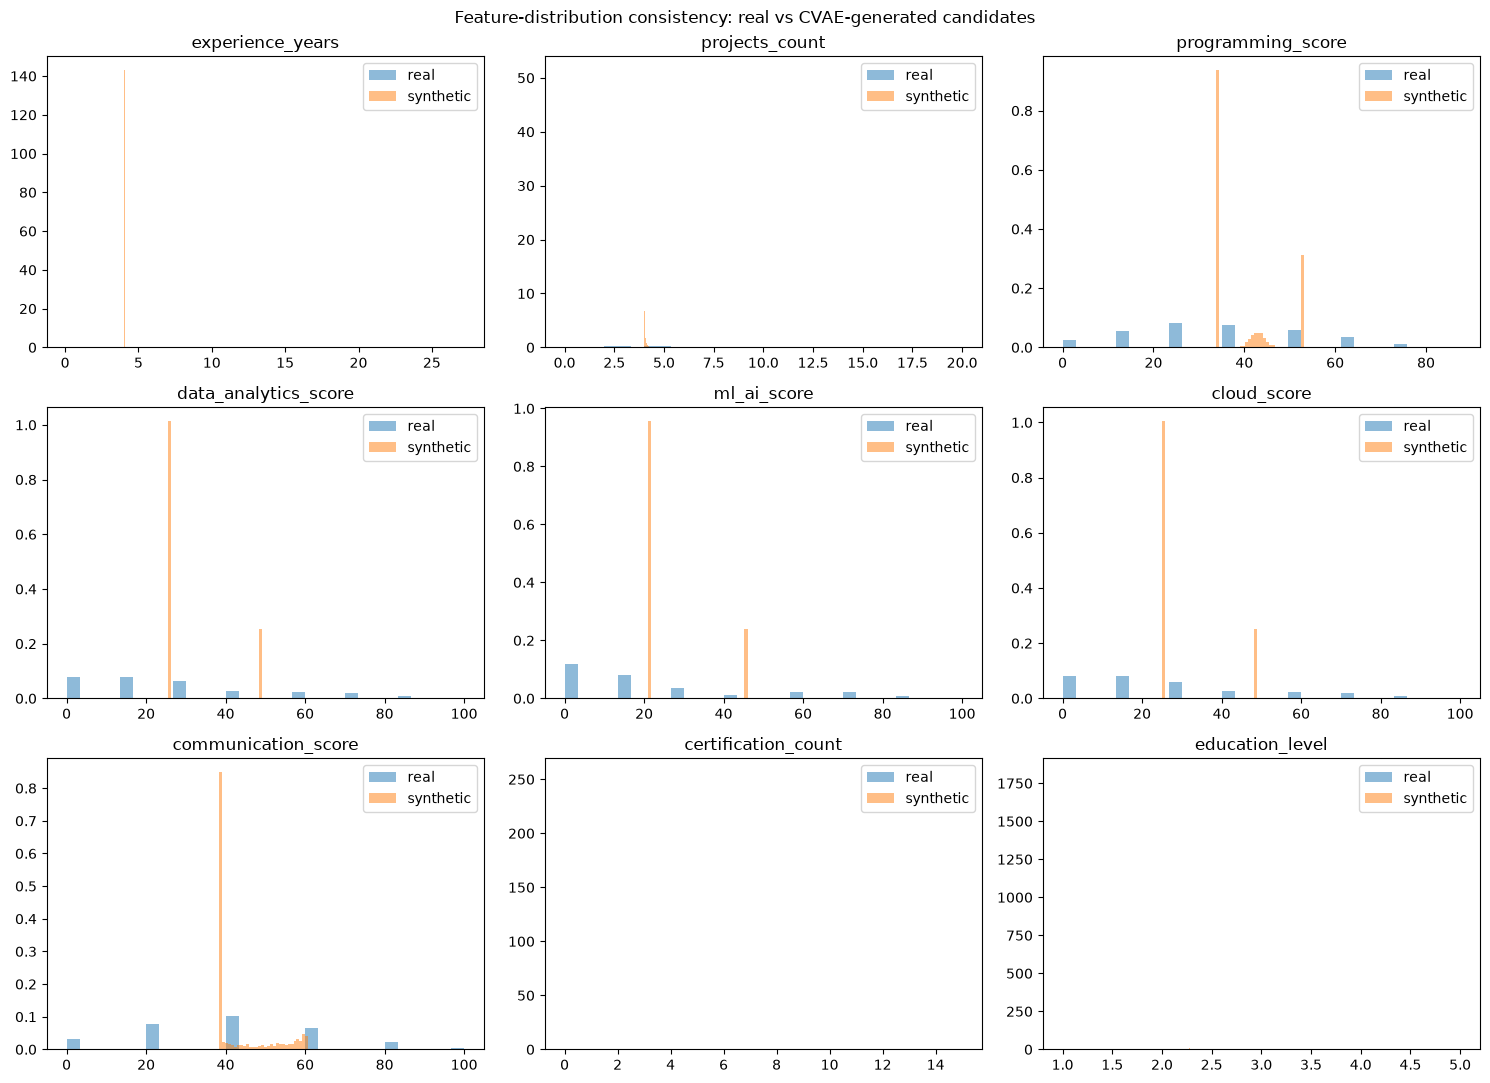

,AI/ML Engineer,Cloud Engineer,Data Analyst,General IT,Software Engineer
experience_years,4.1,4.0,4.1,4.0,4.1
projects_count,4.0,4.0,4.1,4.0,4.0
programming_score,42.9,33.9,33.8,33.9,53.0
data_analytics_score,25.4,25.4,49.1,25.4,25.4
ml_ai_score,46.1,21.0,21.0,21.0,21.0
cloud_score,25.0,48.9,25.0,25.0,25.0
communication_score,38.5,38.5,51.0,50.8,38.5
certification_count,2.4,2.4,2.4,2.4,2.4
education_level,2.3,2.3,2.3,2.3,2.3


In [9]:
fig, ax = plt.subplots(3, 3, figsize=(15, 11))
for a, f in zip(ax.flat, FEATURES):
    a.hist(data[f], bins=30, alpha=0.5, density=True, label="real")
    a.hist(pd.concat(synthetic.values())[f], bins=30, alpha=0.5, density=True, label="synthetic")
    a.set_title(f); a.legend()
plt.suptitle("Feature-distribution consistency: real vs CVAE-generated candidates"); plt.tight_layout(); plt.show()

pd.DataFrame({r: s.mean() for r, s in synthetic.items()}).round(1)

### Role-fit score  =  40% CVAE reconstruction score  +  60% role relevance

In [10]:
def role_fit(candidate):
    x = ((np.array([candidate[f] for f in FEATURES]) - scaler.mean_) / scaler.scale_).astype("float32")[None]
    out = []
    for i, role in enumerate(ROLES):
        c = np.zeros((1, CONDITION_DIM), "float32"); c[0, i] = 1
        z_mean, _ = encoder.predict([x, c], verbose=0)
        mse = float(np.mean((x - decoder.predict([z_mean, c], verbose=0)) ** 2))
        out.append((role, round(100 / (1 + mse), 2)))
    return sorted(out, key=lambda t: -t[1])

example = {"experience_years": 1.5, "projects_count": 4, "programming_score": 30, "data_analytics_score": 60,
           "ml_ai_score": 90, "cloud_score": 45, "communication_score": 70, "certification_count": 3, "education_level": 2}
pd.DataFrame(role_fit(example), columns=["Role", "CVAE score (%)"])

,Role,CVAE score (%)
0,AI/ML Engineer,48.75
1,Data Analyst,47.62
2,General IT,43.29
3,Cloud Engineer,41.34
4,Software Engineer,37.74


### Evaluation matrix — reconstruction error and role prediction

* **Reconstruction MSE** (standardised feature space) with the true role as condition.
* **Role prediction:** the role whose condition gives the lowest reconstruction error — the CVAE part of the app's
  role-fit score. Accuracy, macro precision / recall / F1, classification report and confusion matrix.

Both the model trained in this notebook and the **shipped app model** (`vae_model.h5` + `scaler.json`, loaded and never
overwritten) are scored on the same validation candidates.

In [11]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)

def cvae_role_errors(encode, decode, X, n_roles):
    errors = []
    for i in range(n_roles):
        c = np.zeros((len(X), n_roles), "float32"); c[:, i] = 1
        recon = decode.predict([encode(X, c), c], verbose=0)
        errors.append(np.mean((X - recon) ** 2, axis=1))
    return np.stack(errors, axis=1)

def summary_row(name, errors, y_true):
    y_pred = errors.argmin(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"model": name, "reconstruction MSE (true role)": float(errors[np.arange(len(y_true)), y_true].mean()),
            "role accuracy": accuracy_score(y_true, y_pred), "precision (macro)": p, "recall (macro)": r, "F1 (macro)": f}

y_val = C_val.argmax(1)
evaluations = {"Notebook model (this run)": cvae_role_errors(
    lambda X, c: encoder.predict([X, c], verbose=0)[0], decoder, X_val, len(ROLES))}

if not USE_KAGGLE:      # the shipped model is conditioned on the 5 RecruitGen roles
    with open("scaler.json") as f:
        app_scaler = json.load(f)
    try:
        app_cvae = keras.models.load_model("vae_model.h5", compile=False, custom_objects={"Sampling": Sampling})
    except Exception:
        app_cvae = build_cvae(); app_cvae.load_weights("vae.weights.h5")
    app_encoder = keras.Model(app_cvae.inputs, app_cvae.get_layer("z_mean").output)
    z_in, c_in = keras.Input((LATENT_DIM,)), keras.Input((CONDITION_DIM,))
    h = app_cvae.get_layer("decoder_condition")([z_in, c_in])
    h = app_cvae.get_layer("decoder_dense_2")(app_cvae.get_layer("decoder_dense_1")(h))
    app_decoder = keras.Model([z_in, c_in], app_cvae.get_layer("candidate_reconstruction")(h))
    X_val_app = ((scaler.inverse_transform(X_val) - np.array(app_scaler["mean"])) / np.array(app_scaler["scale"])).astype("float32")
    evaluations["Shipped app model (vae_model.h5)"] = cvae_role_errors(
        lambda X, c: app_encoder.predict([X, c], verbose=0), app_decoder, X_val_app, len(ROLES))

cvae_metrics = pd.DataFrame([summary_row(n, e, y_val) for n, e in evaluations.items()]).set_index("model")
print(f"Validation candidates: {len(y_val)}")
cvae_metrics.round(4)

Validation candidates: 1200


,reconstruction MSE (true role),role accuracy,precision (macro),recall (macro),F1 (macro)
model,,,,,
Notebook model (this run),0.7847,0.8783,0.8792,0.8788,0.8773
Shipped app model (vae_model.h5),1.9566,0.2867,0.3073,0.2873,0.2851


===== Notebook model (this run) =====
                   precision    recall  f1-score   support

   AI/ML Engineer     0.9665    0.9429    0.9545       245
   Cloud Engineer     0.8889    0.9191    0.9038       235
     Data Analyst     0.8291    0.9620    0.8906       237
       General IT     0.7883    0.7202    0.7527       243
Software Engineer     0.9231    0.8500    0.8850       240

         accuracy                         0.8783      1200
        macro avg     0.8792    0.8788    0.8773      1200
     weighted avg     0.8794    0.8783    0.8772      1200

===== Shipped app model (vae_model.h5) =====
                   precision    recall  f1-score   support

   AI/ML Engineer     0.2558    0.2245    0.2391       245
   Cloud Engineer     0.2320    0.3149    0.2671       235
     Data Analyst     0.7107    0.4768    0.5707       237
       General IT     0.2239    0.3704    0.2791       243
Software Engineer     0.1143    0.0500    0.0696       240

         accuracy          

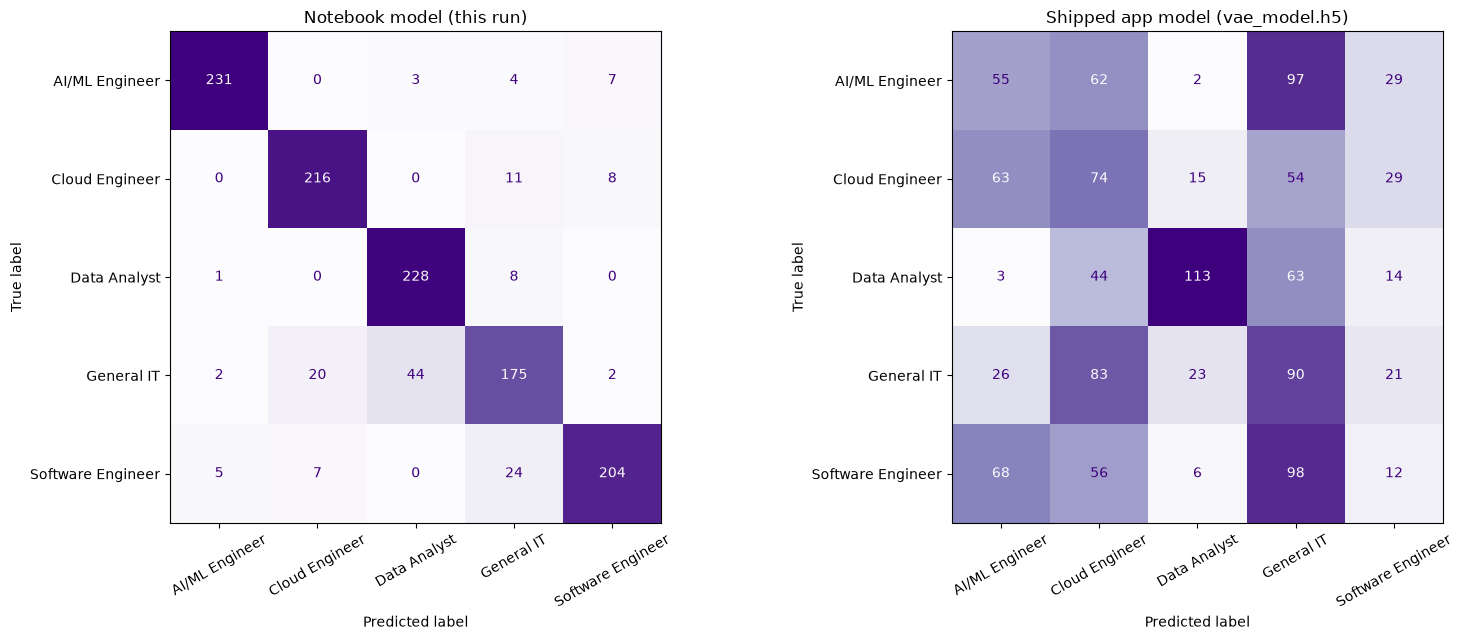

In [12]:
fig, ax = plt.subplots(1, len(evaluations), figsize=(8 * len(evaluations), 6.5), squeeze=False)
for a, (name, errors) in zip(ax[0], evaluations.items()):
    print(f"===== {name} =====")
    print(classification_report(y_val, errors.argmin(1), labels=list(range(len(ROLES))), target_names=ROLES, digits=4, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_val, errors.argmin(1), labels=list(range(len(ROLES)))),
                           display_labels=ROLES).plot(ax=a, xticks_rotation=30, cmap="Purples", colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

## 7. Export — `vae_model.h5` · `vae.weights.h5` · `scaler.json`

In [13]:
cvae.save(os.path.join(OUTPUT_DIR, "vae_model.h5"))
cvae.save_weights(os.path.join(OUTPUT_DIR, "vae.weights.h5"))
with open(os.path.join(OUTPUT_DIR, "scaler.json"), "w") as f:
    json.dump({"mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist()}, f, indent=2)

reloaded = keras.models.load_model(os.path.join(OUTPUT_DIR, "vae_model.h5"), compile=False, custom_objects={"Sampling": Sampling})
print("Reloaded:", reloaded.name, reloaded.input_shape, "->", reloaded.output_shape)
print("Saved:", os.listdir(OUTPUT_DIR))

Reloaded: RecruitGen_CVAE [(None, 9), (None, 5)] -> (None, 9)
Saved: ['scaler.json', 'vae.weights.h5', 'vae_model.h5']


Copy the three files from `outputs/` into `models/cvae/` to use them in the app.

## Final Evaluation — Classification performance + Confusion matrix

* **Accuracy** — overall correctness
* **Precision** — prediction reliability (macro average)
* **Recall** — role detection coverage (macro average)
* **F1-score** — precision-recall balance (macro average)

Role prediction on the 1,200 validation candidates (5 roles); predicted role = lowest reconstruction error. Reconstruction MSE: 0.7847 (this run) vs 1.9566 (shipped).

In [14]:
import pandas as pd

final_matrix = pd.DataFrame(
    {'model': ['Notebook model (this run)', 'Shipped app model (vae_model.h5)'], 'Accuracy': [0.8783, 0.2867], 'Precision': [0.8792, 0.3073], 'Recall': [0.8788, 0.2873], 'F1-score': [0.8773, 0.2851]}
).set_index('model')
final_matrix

,Accuracy,Precision,Recall,F1-score
model,,,,
Notebook model (this run),0.8783,0.8792,0.8788,0.8773
Shipped app model (vae_model.h5),0.2867,0.3073,0.2873,0.2851


### Confusion matrix — this run vs shipped app model (validation set)

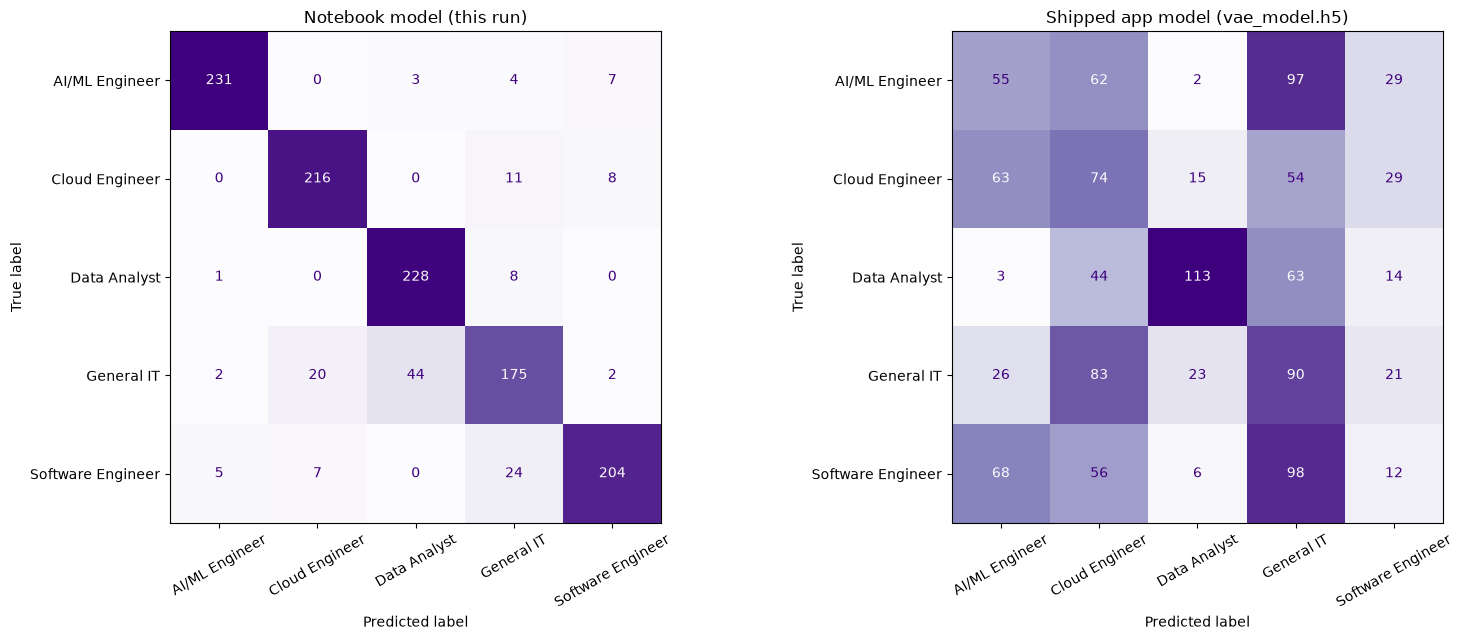